Mетоды по возрастанию сложности реализации:

Bagging нужно только делать случайные выборки и обучать несколько моделей       
Random Forest  добавляется случайный выбор признаков при построении дерева      
Boosting — сложнее, потому что модели обучаются последовательно и требуется обновление весов ошибки     
Stacking — самый сложный, тк требует обучения нескольких базовых моделей и отдельной метамодели     

In [ ]:
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from MyBagging import MyBagging
from MyRandomForest import MyRandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor
import pandas as pd


ImportError: cannot import name 'MyRandomForestRegressor' from 'MyRandomForest' (/Users/maryc/PycharmProjects/PythonProject/инструменты анализа данных/2 sem/1-4 task/MyRandomForest.py)

In [ ]:
X, y = make_regression(n_samples=500, n_features=5, noise=20)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y)


In [ ]:
model = MyBagging(n_estimators=20, max_depth=5)


In [ ]:
model.fit(X_train, y_train)


In [ ]:
pred = model.predict(X_test)


In [ ]:
r2_score(y_test, pred)

0.8857106596909337

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
np.random.seed(42)
X = np.linspace(0, 10, 100).reshape(-1, 1)
y = np.sin(X).ravel() + np.random.normal(0, 0.2, X.shape[0])

In [ ]:
bagging = MyBagging(n_estimators=20, max_depth=3, random_state=42)
bagging.fit(X, y)

In [ ]:
y_pred = bagging.predict(X)


In [ ]:
r2_score(y, y_pred)

0.9083785692141528

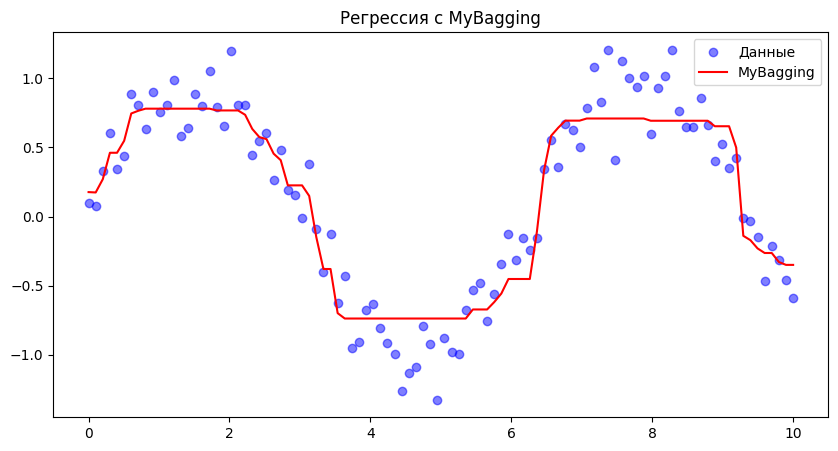

In [ ]:
plt.figure(figsize=(10, 5))
plt.scatter(X, y, color='blue', alpha=0.5, label='Данные')
plt.plot(X, y_pred, color='red', label='MyBagging')
plt.title("Регрессия с MyBagging")
plt.legend()
plt.show()

In [ ]:
sk_bagging = BaggingRegressor(
    estimator=DecisionTreeRegressor(max_depth=3), 
    n_estimators=20,
    random_state=42
)
sk_bagging.fit(X, y)
y_pred_skb = sk_bagging.predict(X)


In [ ]:
r2_skb = r2_score(y, y_pred_skb)
r2_skb

0.9105947156574477

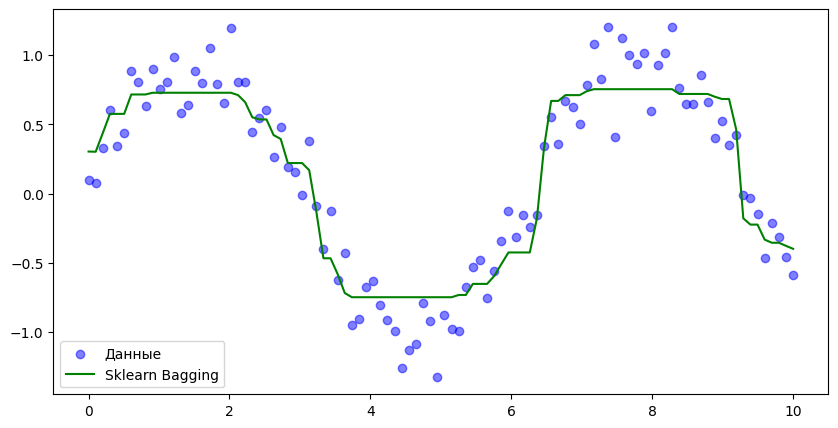

In [ ]:
plt.figure(figsize=(10, 5))
plt.scatter(X, y, color='blue', alpha=0.5, label='Данные')
plt.plot(X, y_pred_skb, color='green', label='Sklearn Bagging')
plt.legend()
plt.show()


In [ ]:
df = pd.DataFrame(np.hstack([X, y.reshape(-1, 1)]), columns=['X', 'y'])

In [ ]:
my_rf = MyRandomForestRegressor(n_trees=20, max_depth=3)
my_rf.fit(df)
y_pred_my = my_rf.predict(df)

NameError: name 'MyRandomForestRegressor' is not defined

In [ ]:
r2_score(y, y_pred_my)
r2_score

In [ ]:
sk_rf = RandomForestRegressor(n_estimators=20, max_depth=3, random_state=42)
sk_rf.fit(X, y)
y_pred_skrf = sk_rf.predict(X)

In [ ]:
r2_skrf = r2_score(y, y_pred_skrf)
r2_skrf

0.9105947156574477

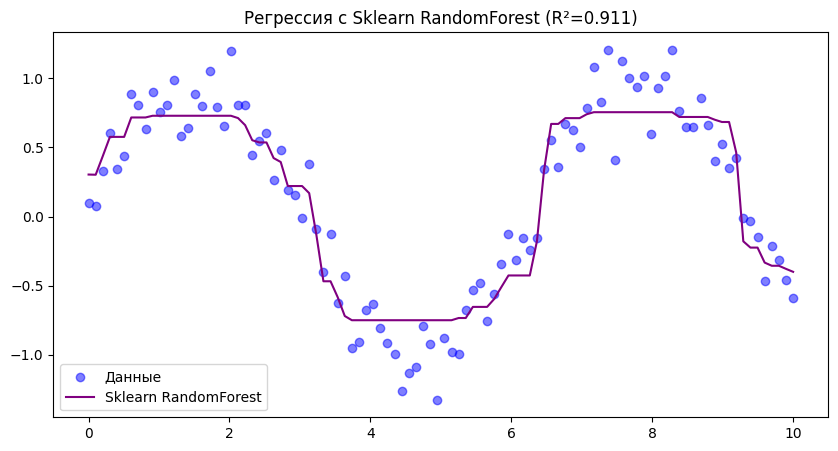

In [ ]:
plt.figure(figsize=(10, 5))
plt.scatter(X, y, color='blue', alpha=0.5, label='Данные')
plt.plot(X, y_pred_skrf, color='purple', label='Sklearn RandomForest')
plt.plot(X, y_pred_my, color='red', linestyle='--', label='My RandomForest')
plt.legend()
plt.show()